# Gaussian Process

A Gaussian process gives a predictive mean and standard deviation for each recipe. The length scale and observation noise are fixed here.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Estimator

The constructor below fixes the model used in every fold.

In [2]:
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from gallery.tabular import concrete_split, regression_report

model = make_pipeline(
    StandardScaler(),
    GaussianProcessRegressor(kernel=RBF(2.5) + WhiteKernel(0.09), optimizer=None, normalize_y=True),
)

## Data and split

All ages of a concrete recipe stay in the same partition. Five training folds also keep recipes together. The final test uses unseen mixes.

In [3]:
X, X_test, y, y_test, groups = concrete_split()

## Held-out predictions

The table includes a training-only baseline. Both panels use the untouched test observations.

Training: 824 observations across 341 recipes. Test: 206 observations.
Training folds, mean R² 0.832, MAE 4.92 MPa
                  R²  MAE (MPa)  RMSE (MPa)  Median AE (MPa)  Bias, pred − obs (MPa)
Model          0.827      5.324       7.182            4.084                  -1.304
Training mean -0.002     14.236      17.267           13.145                  -0.829
90% interval coverage: 0.845; mean width: 19.11 MPa


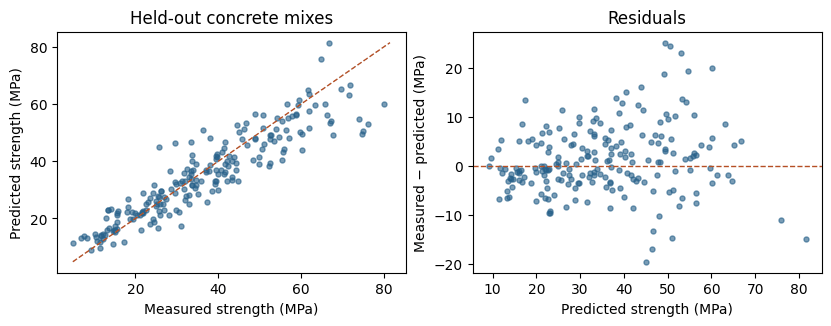

In [4]:
predictions = regression_report(model, X, X_test, y, y_test, groups)
from scipy.stats import norm

centre, sd = model.predict(X_test, return_std=True)
radius = norm.ppf(0.95) * sd
covered = (abs(y_test - centre) <= radius).mean()
print(f"90% interval coverage: {covered:.3f}; mean width: {2 * radius.mean():.2f} MPa")
plt.show()

## Reading the result

Use empirical coverage and interval width together. A wide interval can cover most batches and still have little practical precision.

## References

[scikit-learn, GaussianProcessRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html)

[I-Cheng Yeh, Concrete Compressive Strength (UCI), CC BY 4.0](https://doi.org/10.24432/C5PK67)